In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Loan_status_modified.csv")

In [3]:
df.head(5)

,Gender,Married,ApplicantIncome,LoanAmount,Loan_Status,Occupation,SalaryBand,Qualification
0,Female,No,61995,364076,N,Employee,Medium,Diploma
1,Female,Yes,50015,299048,N,Employee,Medium,Master
2,Female,No,24835,67847,N,Shopkeeper,Low,Diploma
3,Female,Yes,25546,48758,N,Teacher,Low,High School
4,Male,No,38546,78034,N,Engineer,Medium,PhD


In [4]:
print("Dataset size:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())

Dataset size: (50000, 8)

Columns: ['Gender', 'Married', 'ApplicantIncome', 'LoanAmount', 'Loan_Status', 'Occupation', 'SalaryBand', 'Qualification']

Missing values:
 Gender             0
Married            0
ApplicantIncome    0
LoanAmount         0
Loan_Status        0
Occupation         0
SalaryBand         0
Qualification      0
dtype: int64


In [5]:
df["Loan_Status"].value_counts()

Loan_Status
N    25000
Y    25000
Name: count, dtype: int64

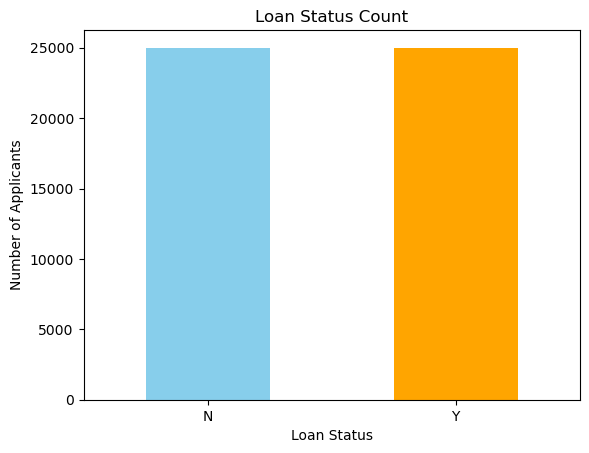

In [6]:
df["Loan_Status"].value_counts().plot(kind="bar", color=["skyblue", "orange"])

plt.title("Loan Status Count")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()

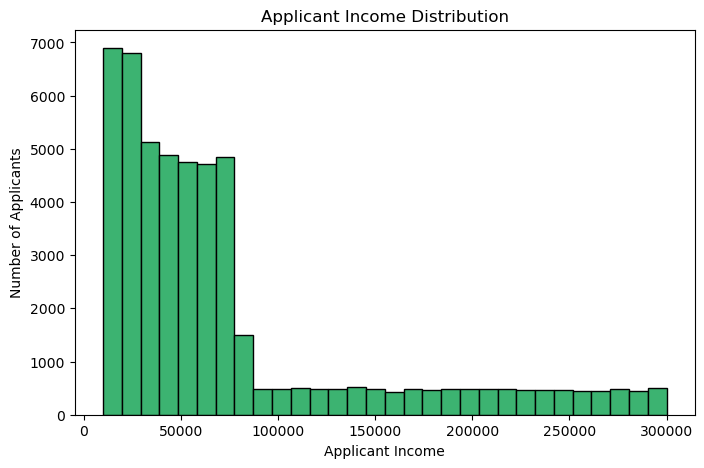

In [7]:
plt.figure(figsize=(8, 5))

plt.hist(df["ApplicantIncome"], bins=30, color="mediumseagreen", edgecolor="black")

plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.show()

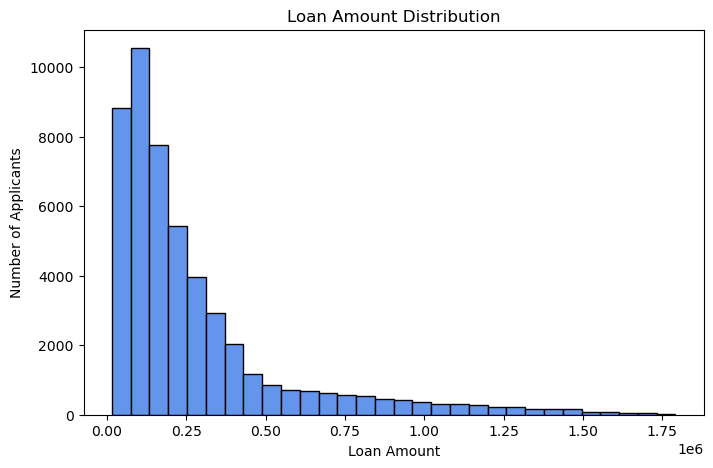

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["LoanAmount"], bins=30, color="cornflowerblue", edgecolor="black")
plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applicants")
plt.show()

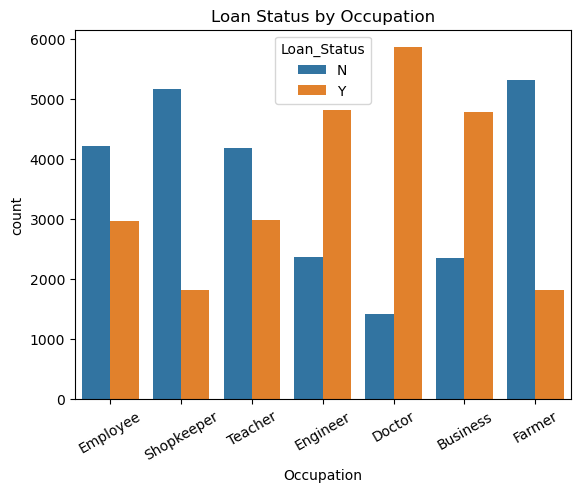

In [9]:
sns.countplot(data=df, x="Occupation", hue="Loan_Status")
plt.title("Loan Status by Occupation")
plt.xticks(rotation=30)
plt.show()

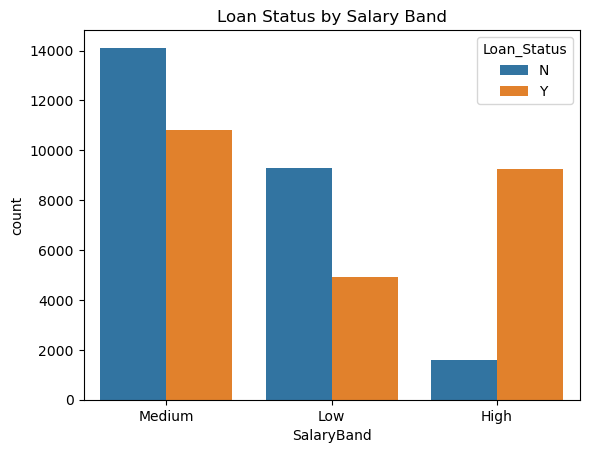

In [10]:
sns.countplot(data=df, x="SalaryBand", hue="Loan_Status")
plt.title("Loan Status by Salary Band")
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 40000
Testing rows: 10000


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_columns = X.select_dtypes(include="object").columns
numeric_columns = X.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer([
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
    ("numbers", StandardScaler(), numeric_columns)
])

X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

print("Data ready for models!")

Data ready for models!


Logistic Regression F1: 0.7869578343564456


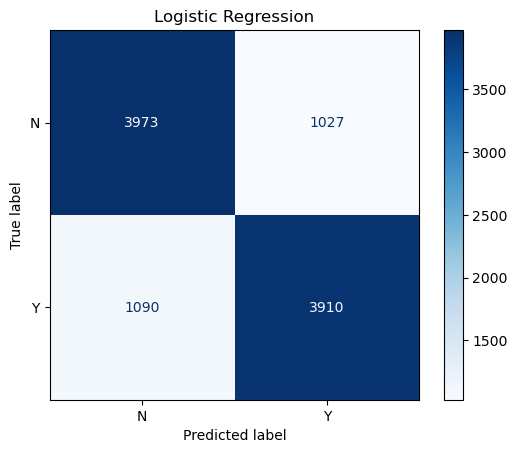

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_ready, y_train)

log_predictions = log_model.predict(X_test_ready)

print("Logistic Regression F1:", f1_score(y_test, log_predictions, pos_label="Y"))

ConfusionMatrixDisplay.from_predictions(
    y_test, log_predictions, labels=["N", "Y"], cmap="Blues"
)
plt.title("Logistic Regression")
plt.show()

In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

log_probabilities = log_model.predict_proba(X_test_ready)[:, 1]

print("Accuracy:", accuracy_score(y_test, log_predictions))
print("Precision:", precision_score(y_test, log_predictions, pos_label="Y"))
print("Recall:", recall_score(y_test, log_predictions, pos_label="Y"))
print("F1 Score:", f1_score(y_test, log_predictions, pos_label="Y"))
print("ROC-AUC:", roc_auc_score(y_test, log_probabilities))

print("\nClassification Report:\n")
print(classification_report(y_test, log_predictions))

Accuracy: 0.7883
Precision: 0.7919789345756533
Recall: 0.782
F1 Score: 0.7869578343564456
ROC-AUC: 0.8756014799999999

Classification Report:

              precision    recall  f1-score   support

           N       0.78      0.79      0.79      5000
           Y       0.79      0.78      0.79      5000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000



Accuracy: 0.8318
Precision: 0.832598235765838
Recall: 0.8306
F1 Score: 0.8315979175010012
ROC-AUC: 0.91475248

Confusion Matrix:


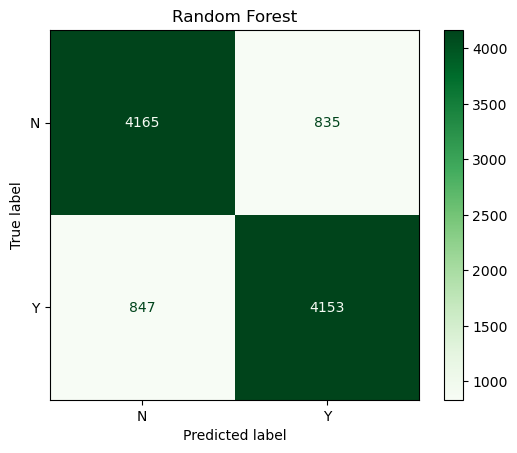

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_ready, y_train)

rf_predictions = rf_model.predict(X_test_ready)
rf_probabilities = rf_model.predict_proba(X_test_ready)[:, 1]

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, pos_label="Y"))
print("Recall:", recall_score(y_test, rf_predictions, pos_label="Y"))
print("F1 Score:", f1_score(y_test, rf_predictions, pos_label="Y"))
print("ROC-AUC:", roc_auc_score(y_test, rf_probabilities))

print("\nConfusion Matrix:")
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions, labels=["N", "Y"], cmap="Greens"
)
plt.title("Random Forest")
plt.show()

Accuracy: 0.8325
Precision: 0.8162450066577897
Recall: 0.8582
F1 Score: 0.8366968899288291
ROC-AUC: 0.917561


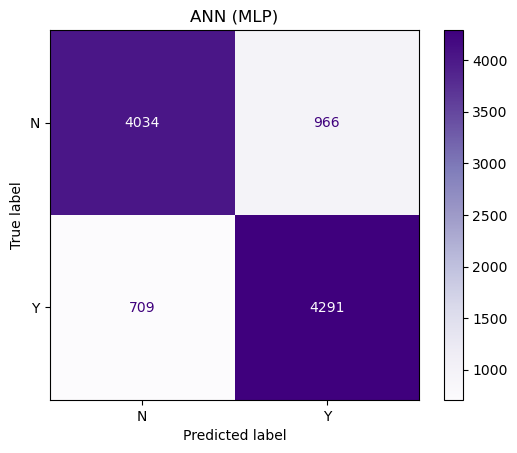

In [18]:
from sklearn.preprocessing import LabelEncoder
from sklearn.neural_network import MLPClassifier

label_encoder = LabelEncoder()
y_train_num = label_encoder.fit_transform(y_train)

ann_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=300,
    early_stopping=True,
    random_state=42
)

ann_model.fit(X_train_ready, y_train_num)

ann_predictions_num = ann_model.predict(X_test_ready)
ann_predictions = label_encoder.inverse_transform(ann_predictions_num.astype(int))
y_class_number = label_encoder.transform(["Y"])[0]
ann_probabilities = ann_model.predict_proba(X_test_ready)[:, y_class_number]

print("Accuracy:", accuracy_score(y_test, ann_predictions))
print("Precision:", precision_score(y_test, ann_predictions, pos_label="Y"))
print("Recall:", recall_score(y_test, ann_predictions, pos_label="Y"))
print("F1 Score:", f1_score(y_test, ann_predictions, pos_label="Y"))
print("ROC-AUC:", roc_auc_score(y_test, ann_probabilities))

ConfusionMatrixDisplay.from_predictions(
    y_test, ann_predictions, labels=["N", "Y"], cmap="Purples"
)
plt.title("ANN (MLP)")
plt.show()

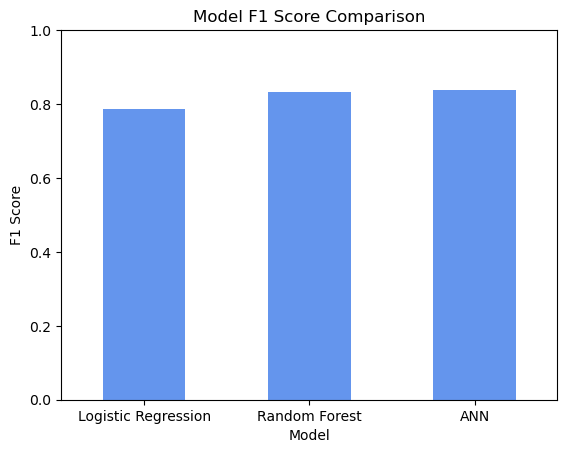

,Model,F1 Score
0,Logistic Regression,0.786958
1,Random Forest,0.831598
2,ANN,0.836697


In [19]:
scores = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "ANN"],
    "F1 Score": [
        f1_score(y_test, log_predictions, pos_label="Y"),
        f1_score(y_test, rf_predictions, pos_label="Y"),
        f1_score(y_test, ann_predictions, pos_label="Y")
    ]
})

scores.plot(x="Model", y="F1 Score", kind="bar", color="cornflowerblue", legend=False)

plt.title("Model F1 Score Comparison")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

scores